# Session 2 lab: Can we trust the sales table?

<p class="lead">
Turn a vague request into a clear question, take the retail table apart, and prove you can count its orders correctly before anyone draws a chart.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/02_data_and_grain_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

The head of a retail business says:

> *"Sales feel uneven across our customer groups. I need to know where to look first. But before you show me any chart: can I trust these numbers? How many orders did we actually have?"*

This is not yet a question you can answer with data, and a wrong count at this stage spoils every later chart. Today you turn the request into a question and build trust in the data.

> **About the data**
>
> We use the **Superstore** sample published by Tableau. It describes a **fictitious** company, not a real one. Sales and Profit are in **source monetary units**: the file does not state a currency, so we never label it as dollars, rupees or anything else.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G7 |
| **Independent tasks** | Same skills, new questions, on your own or in pairs | I1–I6 |
| **Challenge** | Harder reasoning and debugging | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Write a business question that names a decision, a population, a period and a measure.
2. Explain what the setup cell's `load_orders()` does, step by step.
3. State the **grain** of the table and count **orders** correctly with `nunique()`.
4. Write a **data dictionary** and run a **quality checklist** across five dimensions.
5. Explain what the returns flag does and does not tell you.
6. Check one order by hand and keep a **preparation log**.

**Evidence you keep:** your question, grain statement, data dictionary, quality checklist, preparation log, one hand-checked order and a first chart with its filters written down.

Before you start, work through the [Session 2 lecture](02_data_and_grain_lecture.md) and the [Session 1 lab](01_why_data_analytics_lab.md), and have your evidence log open.

---

## Guided practice

### G1 (Core): From request to question

A good analytical question answers four things:

| Part | Ask yourself | Example |
|---|---|---|
| **Decision** | What will someone do differently? | Choose one customer segment to investigate next month |
| **Population** | Which records count? | All order lines in the course data |
| **Period** | Which dates? | Orders placed in 2023, 2024 and 2025 |
| **Measure** | What will we compare? | Sales by customer segment |

> *"Which customer segment had the highest Sales for orders placed in 2023–2025, so we can choose one segment to investigate next month?"*

> **Your turn**
>
> Rewrite the head's request as your own one-sentence question, using the four parts. Write it in your evidence log.

---

### G2 (Core): Load the data

Run the setup cell first. It downloads the sample from Tableau's website, checks it is exactly the version this course was written for, and prepares the table. In G4 you will open it up and see what each step does.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


Now load the table into a variable called `df` and look at the first rows.

In [2]:
df = load_orders()
df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,segment,country_region,region,category,...,product_name,sales,quantity,discount,profit,returned_order_flag,customer_analysis_eligible,customer_order_conflict,order_to_ship_days,order_month
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Consumer,United States,Central,Office Supplies,...,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.45,2,0.20,5.55,0,1,0,4,2023-01-01
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Home Office,United States,Central,Office Supplies,...,GBC Standard Plastic Binding Systems Combs,3.54,2,0.80,-5.49,0,1,0,4,2023-01-01
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Home Office,United States,Central,Office Supplies,...,Avery 508,11.78,3,0.20,4.27,0,1,0,4,2023-01-01
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Home Office,United States,Central,Office Supplies,...,SAFCO Boltless Steel Shelving,272.74,3,0.20,-64.77,0,1,0,4,2023-01-01
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Consumer,United States,East,Office Supplies,...,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.54,3,0.20,4.88,0,1,0,7,2023-01-01


---

### G3 (Core): Size, column types and dates

In [3]:
print("Rows, columns:", df.shape)
df.dtypes

Rows, columns: (6815, 22)


row_id                                 int64
order_id                              object
order_date                    datetime64[ns]
ship_date                     datetime64[ns]
ship_mode                             object
customer_id                           object
segment                               object
country_region                        object
region                                object
category                              object
sub_category                          object
product_id                            object
product_name                          object
sales                                float64
quantity                               int64
discount                             float64
profit                               float64
returned_order_flag                    int64
customer_analysis_eligible             int64
customer_order_conflict                int64
order_to_ship_days                     int64
order_month                   datetime64[ns]
dtype: obj

Check the types make sense:

- `order_id`, `segment`, `region` are text (`object`).
- `sales`, `profit`, `discount` are decimals (`float64`); `quantity` is a whole number.
- `order_date`, `ship_date`, `order_month` are dates (`datetime64`).

> **IDs are not amounts**
>
> `row_id` is stored as a number, but adding it up means nothing. It is an identifier: a **nominal** variable, whatever its storage type.

Which dates are included?

In [4]:
print("First order date:", df["order_date"].min().date())
print("Last order date: ", df["order_date"].max().date())

First order date: 2023-01-03
Last order date:  2025-12-31


---

### G4 (Core): What `load_orders()` does

So far you used `load_orders()` without looking inside. Now we open it up. You do not need to memorise this code; you need to know **what was changed** between the original file and `df`, so you can explain your numbers.

The function does seven things:

| Step | What happens | Why |
|---|---|---|
| 1 | Reads the **Orders** and **Returns** sheets from the Excel file | These are the raw tables |
| 2 | Finds orders that have more than one Customer ID | A known data issue, flagged before filtering |
| 3 | Keeps orders placed from **2023-01-01 to 2025-12-31** | Gives the course a fixed, complete period |
| 4 | Renames columns to short lowercase names | Easier to type: `order_id` instead of `"Order ID"` |
| 5 | Adds `returned_order_flag` | Marks orders on the returns list |
| 6 | Adds `customer_order_conflict` and `customer_analysis_eligible` | Marks the customer-ID issue from step 2 |
| 7 | Adds `order_to_ship_days` and `order_month`, then keeps 22 columns sorted by `row_id` | Handy derived columns |

The cells below repeat each step on its own so you can see the effect.

#### Step 1: Read the raw sheets

`SOURCE_FILE` is the Excel file the setup cell downloaded. `pd.read_excel` reads one sheet into a DataFrame.

In [5]:
raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

print("Raw Orders sheet, rows and columns:", raw.shape)
print("Returns sheet, rows and columns:   ", returns.shape)
print("Order dates in the raw file:", raw["Order Date"].min().date(), "to", raw["Order Date"].max().date())

Raw Orders sheet, rows and columns: (10194, 21)
Returns sheet, rows and columns:    (296, 2)
Order dates in the raw file: 2023-01-03 to 2026-12-30


The raw file has more rows than `df`, and its dates run further. The Returns sheet is just a list of order IDs:

In [6]:
returns.head(3)

,Order ID,Returned
0,US-2023-100762,Yes
1,US-2023-100867,Yes
2,US-2023-102652,Yes


#### Step 2: Find orders with more than one customer

Every order should belong to one customer. The code counts the different Customer IDs inside each order and keeps the orders where that count is above 1. This is done on the **whole raw file**, before any filtering, so no conflict is hidden by the date filter.

In [7]:
ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
conflict_orders = set(ids_per_order[ids_per_order > 1].index)
conflict_orders

{'CA-2025-121465', 'CA-2026-130494'}

#### Step 3: Keep orders placed 2023 to 2025

The filter keeps rows whose **Order Date** is on or after 1 January 2023 and before 1 January 2026. It looks at the order date only.

In [8]:
in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
print("Rows kept:   ", in_scope.sum())
print("Rows dropped:", (~in_scope).sum())

Rows kept:    6815
Rows dropped: 3379


The ship date is **not** filtered. An order placed late in 2025 may ship in early 2026, and it stays in, because the order date defines the period:

In [9]:
print("Lines in df that shipped in 2026:", (df["ship_date"] >= "2026-01-01").sum())

Lines in df that shipped in 2026: 34


#### Step 4: Rename columns

`rename` swaps the original names (with spaces and capitals) for short names. Four raw columns are not kept at all, because the course does not need them:

In [10]:
kept_raw = ["Row ID", "Order ID", "Order Date", "Ship Date", "Ship Mode", "Customer ID",
            "Segment", "Country/Region", "Region", "Category", "Sub-Category", "Product ID",
            "Product Name", "Sales", "Quantity", "Discount", "Profit"]
[col for col in raw.columns if col not in kept_raw]

['Customer Name', 'City', 'State/Province', 'Postal Code']

#### Step 5: The returns flag

`isin` asks, for each row, "is this order ID on the returns list?". The answer `True`/`False` is turned into `1`/`0`. A three-line order on the list gets a `1` on **all three lines**.

#### Step 6: The customer-conflict flags

The same `isin` trick marks every line of a conflicted order with `customer_order_conflict = 1`. `customer_analysis_eligible` is the opposite (`1 - conflict`). These lines stay in all Sales and order counts; they are left out only when we later analyse individual customers.

In [11]:
df.groupby("customer_order_conflict")["order_id"].nunique()

customer_order_conflict
0    3387
1       1
Name: order_id, dtype: int64

Compare this with the output of Step 2: not every conflicted order in the raw file was placed inside the course period, so fewer of them appear in `df`.

#### Step 7: Two derived date columns

- `order_to_ship_days` = ship date minus order date, in whole days.
- `order_month` = the first day of the order's month, used to group by month.

In [12]:
df[["order_id", "order_date", "ship_date", "order_to_ship_days", "order_month"]].head(3)

,order_id,order_date,ship_date,order_to_ship_days,order_month
0,US-2023-103800,2023-01-03,2023-01-07,4,2023-01-01
1,US-2023-112326,2023-01-04,2023-01-08,4,2023-01-01
2,US-2023-112326,2023-01-04,2023-01-08,4,2023-01-01


> **Remember**
>
> The original Excel file is never changed. `load_orders()` builds a fresh, prepared copy every time you run it, so anyone can repeat your work and get the same table.

---

### G5 (Core): Find the grain and count orders

**Grain** means: what does one row represent?

Look at all the rows of one order:

In [13]:
df[df["order_id"] == "US-2023-100762"][["row_id", "order_id", "segment", "category", "product_id", "sales"]]

,row_id,order_id,segment,category,product_id,sales
1684,1685,US-2023-100762,Corporate,Office Supplies,OFF-AR-10000380,151.92
1688,1689,US-2023-100762,Corporate,Office Supplies,OFF-LA-10003930,196.62
1690,1691,US-2023-100762,Corporate,Office Supplies,OFF-PA-10001815,144.12
1691,1692,US-2023-100762,Corporate,Office Supplies,OFF-PA-10004082,15.96


Same `order_id`, different `row_id` and product: each row is **one product line within an order**.

> **Write your grain statement**
>
> Complete this sentence in your log: *"One row in df represents one ______ , identified by ______ ."*

Predict before you run the next cell: will the number of rows equal the number of orders?

In [14]:
print("Rows (order lines):", len(df))
print("Different orders:  ", df["order_id"].nunique())

Rows (order lines): 6815
Different orders:   3388


> **Remember**
>
> `len(df)` counts **rows**. `df["order_id"].nunique()` counts **different orders**. Use the second one whenever a question is about orders.

How many lines do orders usually have? `groupby("order_id").size()` counts the lines in each order; `value_counts()` then counts how many orders have 1 line, 2 lines, and so on.

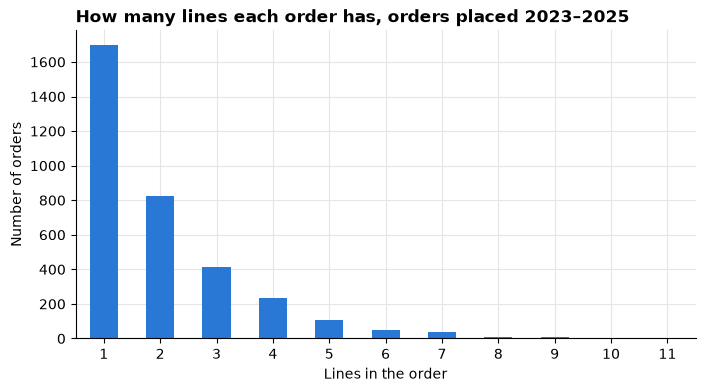

In [15]:
lines_per_order = df.groupby("order_id").size().value_counts().sort_index()
lines_per_order.plot(kind="bar", title="How many lines each order has, orders placed 2023–2025")
plt.xlabel("Lines in the order")
plt.ylabel("Number of orders")
plt.xticks(rotation=0)
plt.show()

Many orders have one line, but plenty have several. That is why `len(df)` overstates the number of orders.

---

### G6 (Core): What the returns flag means

`returned_order_flag` is `1` when an order is on the source's **returns list**. Be careful with what it does **not** tell you:

- It has **no** return date, quantity or refund amount.
- A `0` means **not on the list**. It does not prove the order was never returned.
- The flag repeats on **every line** of a listed order.

The order you looked at in G5 is on the list. See how the flag repeats:

In [16]:
df[df["order_id"] == "US-2023-100762"][["row_id", "order_id", "returned_order_flag"]]

,row_id,order_id,returned_order_flag
1684,1685,US-2023-100762,1
1688,1689,US-2023-100762,1
1690,1691,US-2023-100762,1
1691,1692,US-2023-100762,1


Now compare two ways of counting:

In [17]:
flagged = df[df["returned_order_flag"] == 1]
print("Sum of the flag (counts LINES):        ", df["returned_order_flag"].sum())
print("Distinct orders on the returns list:   ", flagged["order_id"].nunique())

Sum of the flag (counts LINES):         511
Distinct orders on the returns list:    191


> **A common mistake**
>
> Adding up `returned_order_flag` counts **lines** of listed orders, not orders. To count orders on the returns list, filter to flag 1 and use `nunique()` on `order_id`, as in the second line of the output above.

Say "orders on the returns list", not "returned orders" or "return rate": the list tells us membership only.

---

### G7 (Core): A first chart, with a filter

Total Sales for each customer segment:

In [18]:
sales_by_segment = df.groupby("segment")["sales"].sum().sort_values()
sales_by_segment

segment
Home Office   277,656.95
Corporate     467,562.02
Consumer      835,747.86
Name: sales, dtype: float64

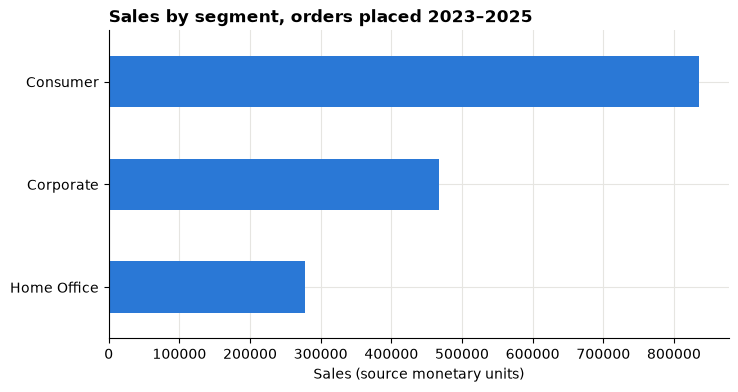

In [19]:
sales_by_segment.plot(kind="barh", title="Sales by segment, orders placed 2023–2025")
plt.xlabel("Sales (source monetary units)")
plt.ylabel("")
plt.show()

The same chart for one region only. The filter keeps rows where `region` is `"West"`.

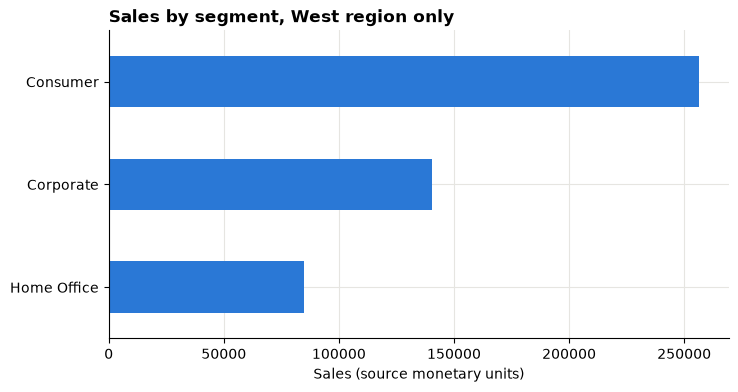

In [20]:
west = df[df["region"] == "West"]
west.groupby("segment")["sales"].sum().sort_values().plot(
    kind="barh", title="Sales by segment, West region only"
)
plt.xlabel("Sales (source monetary units)")
plt.ylabel("")
plt.show()

> **Write it down**
>
> Every time you filter, record it in your evidence log. A chart without its filters written down is easy to misread later.

---

## Independent tasks

### I1 (Core): Write a data dictionary

pandas can fill in the mechanical part of a dictionary. Run the cell to profile every column.

In [21]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "distinct": df.nunique(),
    "example": df.iloc[0],
})
profile

,dtype,missing,distinct,example
row_id,int64,0,6815,1
order_id,object,0,3388,US-2023-103800
order_date,datetime64[ns],0,918,2023-01-03 00:00:00
ship_date,datetime64[ns],0,989,2023-01-07 00:00:00
ship_mode,object,0,4,Standard Class
customer_id,object,0,793,DP-13000
segment,object,0,3,Consumer
country_region,object,0,2,United States
region,object,0,4,Central
category,object,0,3,Office Supplies


Now add the human part. The next cell has three columns filled in as examples.

1. Add at least **eight more** columns, including `order_id`, `quantity`, `profit`, `discount`, `returned_order_flag` and `order_to_ship_days`.
2. For each, write its meaning, its **level of measurement** (nominal, ordinal, interval or ratio) and whether you can add it up across rows.
3. Run the cell to see your dictionary as a table.

> **Your turn:** change the code in the next cell and run it again.

In [22]:
# Add one entry per column: "column": ("meaning", "level of measurement", "can you add it up?")
dictionary_notes = {
    "row_id": ("Unique number for each order line", "nominal", "No, it is an identifier"),
    "segment": ("Customer group", "nominal", "No, use it to group"),
    "sales": ("Sales reported for the line, source monetary units", "ratio", "Yes"),
}

my_dictionary = pd.DataFrame.from_dict(
    dictionary_notes, orient="index", columns=["meaning", "level", "add up?"]
)
my_dictionary.join(profile[["dtype", "distinct"]])

,meaning,level,add up?,dtype,distinct
row_id,Unique number for each order line,nominal,"No, it is an identifier",int64,6815
segment,Customer group,nominal,"No, use it to group",object,3
sales,"Sales reported for the line, source monetary u...",ratio,Yes,float64,4640


When you have finished, compare your entries with the course dictionary below. Where you disagree, write down why.

| Column | What it is | Can you add it up? |
|---|---|---|
| `row_id` | Unique number for each order line | No, it is an identifier |
| `order_id` | Order identifier; repeats across that order's lines | No, count it with `nunique()` |
| `order_date`, `ship_date` | Calendar dates | No |
| `order_month` | First day of the order's month | No, use it to group |
| `ship_mode` | Shipping service chosen | No, use it to group |
| `customer_id` | Fictitious customer identifier | No |
| `segment` | Customer group: Consumer, Corporate or Home Office | No, use it to group |
| `country_region`, `region` | Location labels | No, use them to group |
| `category`, `sub_category` | Product groups | No, use them to group |
| `product_id`, `product_name` | Product identifier and name | No |
| `sales` | Sales reported for the line, in source monetary units | **Yes** |
| `quantity` | Number of items on the line | **Yes**, but it counts items, not orders |
| `profit` | Profit reported for the line (can be negative) | **Yes** |
| `discount` | Discount value as given in the source | **No**, its base is not documented |
| `returned_order_flag` | 1 if the order is on the returns list, else 0 | Not across lines (see G6) |
| `order_to_ship_days` | Days from order date to ship date | Not as a total; it repeats on every line of an order |
| `customer_analysis_eligible`, `customer_order_conflict` | Flags for the customer-ID issue | Used only for customer analysis later |

> **Discount is not a KPI**
>
> The source does not say what `discount` is a share of. Adding it up or averaging it produces a number nobody can interpret, so we do not use it as a measure.

---

### I2 (Core): Quality checklist across five dimensions

The cell runs one or more checks for each data-quality dimension from the lecture. Read each line of the output and decide: **pass**, **fail** or **pass with a note**.

In [23]:
checks = pd.DataFrame([
    ("Completeness", "Missing values in the whole table", df.isna().sum().sum()),
    ("Validity", "Quantity always above zero", (df["quantity"] > 0).all()),
    ("Validity", "Sales never negative", (df["sales"] >= 0).all()),
    ("Validity", "Segment only Consumer / Corporate / Home Office",
     df["segment"].isin(["Consumer", "Corporate", "Home Office"]).all()),
    ("Consistency", "Ship date never before order date", (df["ship_date"] >= df["order_date"]).all()),
    ("Consistency", "Each order has one order date", (df.groupby("order_id")["order_date"].nunique() == 1).all()),
    ("Consistency", "Orders with more than one customer ID", df.loc[df["customer_order_conflict"] == 1, "order_id"].nunique()),
    ("Uniqueness", "row_id is unique", df["row_id"].is_unique),
    ("Uniqueness", "Fully duplicated rows", df.duplicated().sum()),
    ("Timeliness", "First order date", df["order_date"].min().date()),
    ("Timeliness", "Last order date", df["order_date"].max().date()),
    ("Timeliness", "Calendar months with orders", df["order_month"].nunique()),
], columns=["dimension", "check", "result"])
checks

,dimension,check,result
0,Completeness,Missing values in the whole table,0
1,Validity,Quantity always above zero,True
2,Validity,Sales never negative,True
3,Validity,Segment only Consumer / Corporate / Home Office,True
4,Consistency,Ship date never before order date,True
5,Consistency,Each order has one order date,True
6,Consistency,Orders with more than one customer ID,1
7,Uniqueness,row_id is unique,True
8,Uniqueness,Fully duplicated rows,0
9,Timeliness,First order date,2023-01-03


Copy the table into your evidence log and add two columns: **pass / fail / note** and **what we do about it**. For example, the customer-ID conflicts are a known consistency issue: kept in all order and Sales counts, excluded only from customer-level analysis.

> **Your turn**
>
> Add one more check of your own to the list above (for example: is `order_month` always the first day of the order's month? Is `profit` ever larger than `sales`?). Say which dimension it belongs to.

---

### I3 (Core): Check one order by hand

Pick one order with several lines and add it up yourself.

1. Show each line's `sales` and `profit`.
2. Add the lines up on paper or with a calculator.
3. Compare with what pandas says.

In [24]:
one_order = df[df["order_id"] == "US-2023-100762"]
one_order[["row_id", "product_id", "sales", "profit"]]

,row_id,product_id,sales,profit
1684,1685,OFF-AR-10000380,151.92,45.58
1688,1689,OFF-LA-10003930,196.62,96.34
1690,1691,OFF-PA-10001815,144.12,69.18
1691,1692,OFF-PA-10004082,15.96,7.98


In [25]:
print("pandas total sales: ", round(one_order["sales"].sum(), 2))
print("pandas total profit:", round(one_order["profit"].sum(), 2))

pandas total sales:  508.62
pandas total profit: 219.08


Do your hand totals match the output above? Small differences in the last digit come from rounding.

> **Your turn:** change the code in the next cell and run it again.

In [26]:
# Hand-check a different order.
# 1. Replace the order ID with another one that has several lines,
#    for example one you saw in df.head(20).
# 2. Add up the lines yourself, then compare with the totals printed below.
one_order = df[df["order_id"] == "US-2023-100762"]
print(one_order[["row_id", "product_id", "sales", "profit"]])
print("pandas total sales: ", round(one_order["sales"].sum(), 2))
print("pandas total profit:", round(one_order["profit"].sum(), 2))

      row_id       product_id  sales  profit
1684    1685  OFF-AR-10000380 151.92   45.58
1688    1689  OFF-LA-10003930 196.62   96.34
1690    1691  OFF-PA-10001815 144.12   69.18
1691    1692  OFF-PA-10004082  15.96    7.98
pandas total sales:  508.62
pandas total profit: 219.08


Record the order ID, your hand total and the pandas total in your log.

---

### I4 (Core): Keep a preparation log

Write down every change made to how the data is read or shaped, even small ones. You can keep the log in pandas too:

In [27]:
prep_log = pd.DataFrame([
    {"change": "Kept orders placed 2023-01-01 to 2025-12-31",
     "why": "Fixed course period", "checked": "Min and max order_date"},
    {"change": "Counted orders with order_id.nunique()",
     "why": "Rows are order lines", "checked": "Compared with len(df); hand-checked one order"},
])
prep_log

,change,why,checked
0,Kept orders placed 2023-01-01 to 2025-12-31,Fixed course period,Min and max order_date
1,Counted orders with order_id.nunique(),Rows are order lines,Compared with len(df); hand-checked one order


> **Your turn:** change the code in the next cell and run it again.

In [28]:
# Add one more row to the log: the change you think matters most from G4.
# Fill in the three texts, then run the cell.
prep_log = pd.concat([prep_log, pd.DataFrame([
    {"change": "...", "why": "...", "checked": "..."},
])], ignore_index=True)
prep_log

,change,why,checked
0,Kept orders placed 2023-01-01 to 2025-12-31,Fixed course period,Min and max order_date
1,Counted orders with order_id.nunique(),Rows are order lines,Compared with len(df); hand-checked one order
2,...,...,...


---

### I5 (Stretch): Your own filtered chart

> **Your turn:** change the code in the next cell and run it again.

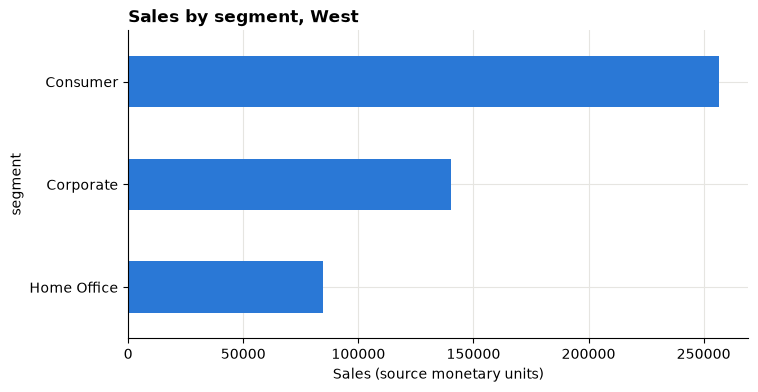

In [29]:
# 1. Change "segment" to "category" to see Sales by product category.
# 2. Change "West" to another region: "East", "Central" or "South".
# 3. Update the title so it says exactly what the chart shows.
selected = df[df["region"] == "West"]
selected.groupby("segment")["sales"].sum().sort_values().plot(kind="barh", title="Sales by segment, West")
plt.xlabel("Sales (source monetary units)")
plt.show()

Write one sentence describing what your chart shows, including its filter. Do not explain *why* yet.

---

### I6 (Stretch): Segment versus category

For each segment: number of rows, number of distinct orders and total sales. `agg` computes several summaries at once.

In [30]:
by_segment = df.groupby("segment").agg(
    rows=("row_id", "count"),
    orders=("order_id", "nunique"),
    sales=("sales", "sum"),
)
by_segment.reset_index()

,segment,rows,orders,sales
0,Consumer,3586,1738,"835,747.86"
1,Corporate,2084,1044,"467,562.02"
2,Home Office,1145,606,"277,656.95"


In [31]:
print("Sum of segment order counts:", by_segment["orders"].sum())
print("Overall distinct orders:    ", df["order_id"].nunique())

Sum of segment order counts: 3388
Overall distinct orders:     3388


The same table for product category:

In [32]:
by_category = df.groupby("category").agg(
    rows=("row_id", "count"),
    orders=("order_id", "nunique"),
    sales=("sales", "sum"),
)
by_category.reset_index()

,category,rows,orders,sales
0,Furniture,1488,1235,"535,434.83"
1,Office Supplies,4093,2516,"478,057.88"
2,Technology,1234,1028,"567,474.11"


In [33]:
print("Sum of category order counts:", by_category["orders"].sum())
print("Overall distinct orders:     ", df["order_id"].nunique())

Sum of category order counts: 4779
Overall distinct orders:      3388


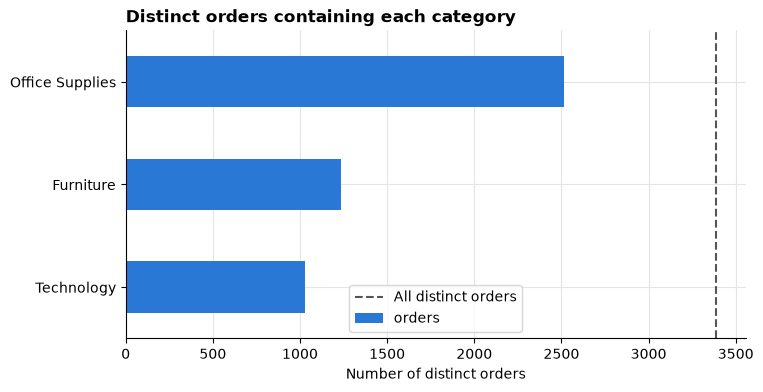

In [34]:
by_category["orders"].sort_values().plot(kind="barh", title="Distinct orders containing each category")
plt.axvline(df["order_id"].nunique(), color="#555555", linestyle="--", label="All distinct orders")
plt.xlabel("Number of distinct orders")
plt.ylabel("")
plt.legend()
plt.show()

Compare the two pairs of numbers in the outputs above.

- In this table every order has exactly one segment, so the segment counts add up to the overall total.
- One order can contain products from **several categories**. That order is counted once in each category it touches, so the category counts add up to **more** than the overall total.

> **Distinct counts do not always add up**
>
> Sales and Profit can be added across groups. Distinct order counts can only be added when every order belongs to exactly one group. Always recount distinct orders at the level you display.

> **Your turn:** change the code in the next cell and run it again.

In [35]:
# Try another grouping.
# 1. Change "category" to "region", then to "sub_category".
# 2. For each, compare the sum of order counts with the overall distinct orders.
#    Which one behaves like segment, and which like category?
by_group = df.groupby("category").agg(
    rows=("row_id", "count"),
    orders=("order_id", "nunique"),
)
print(by_group)
print("Sum of order counts:    ", by_group["orders"].sum())
print("Overall distinct orders:", df["order_id"].nunique())

                 rows  orders
category                     
Furniture        1488    1235
Office Supplies  4093    2516
Technology       1234    1028
Sum of order counts:     4779
Overall distinct orders: 3388


---

## Challenge

### C1 (Challenge): Debugging a colleague's summary

A colleague sends this code and summary:

> *"We had `len(df)` orders, and `df["returned_order_flag"].sum()` of them were returned."*

> **Your turn:** change the code in the next cell and run it again.

In [36]:
# The colleague's code. It runs, but both numbers answer the wrong question.
# 1. Find the two mistakes.
# 2. Fix each line so it counts ORDERS, not lines.
# 3. Rewrite the sentence using careful wording about the returns list.
orders = len(df)
returned = df["returned_order_flag"].sum()
print("We had", orders, "orders, and", returned, "of them were returned.")

We had 6815 orders, and 511 of them were returned.


> **How would you check your fix?**
>
> Compare your corrected numbers with the outputs in G5 and G6. Then pick one listed order and confirm it is counted once, not once per line.

---

### C2 (Challenge): Is the biggest bar the best segment?

A colleague looks at your G7 chart and says:

> *"The biggest bar is the best segment, so we should invest there."*

In two or three sentences, explain why a bigger Sales bar alone does not tell us where to invest. What else would you want to see?

---

## Exit ticket

1. Your one-sentence business question.
2. Your grain statement, and why rows and orders differ in this table.
3. One thing the returns flag cannot tell you.
4. One change `load_orders()` makes to the original file, and why.
5. One thing you are still unsure about.

## Evidence to keep

- [ ] Business question with decision, population, period and measure (G1)
- [ ] Grain statement (G5)
- [ ] Data dictionary with level of measurement for at least eleven columns (I1)
- [ ] Quality checklist with a decision for each check (I2)
- [ ] One hand-checked order (I3)
- [ ] Preparation log (I4)
- [ ] A first chart with its filters written down (G7 or I5)

## After the lab

- Read the [Analytical workflow](../course/workflow.md) page.
- Previous: [Session 2 lecture](02_data_and_grain_lecture.md). Next: Session 3, cleaning and preparing data.